In [1]:
#A6Q1
import math 

#Given data 
r =0.043 
years = [1, 2, 3, 4, 5]
Investment_A = [225, 215, 250, 225, 205]
Investment_B = [220, 225, 250, 250, 210]

def present_value(cashflows, years, r) :
    total = 0
    for i in range(len(cashflows)) :
        c = cashflows[i]
        t = years[i] 
        total += c*math.exp(-r*t) 
    return total 

pv_A = present_value(Investment_A, years, r)
pv_B = present_value(Investment_B, years, r)

print('Present Value of Investment A is : ', pv_A)
print('Present Value of Investment B is : ', pv_B)

if pv_A>pv_B :
    print('Investment A is preferable.')
elif pv_B>pv_A:
    print('Investment B is preferable.')
else:
    print('Both have same present value.')
     


Present Value of Investment A is :  987.3426230630746
Present Value of Investment B is :  1016.8111949550402
Investment B is preferable.


In [12]:
#A6Q2
import math 

#Given Values 
c_rate = 0.08 
F = 100
coupon = F * c_rate
r = 0.11
T = 5 

# (a) Bond's Price 
def bond_price(F, coupon, r, T):
    price = 0
    for t in range(1, T+1):
        price += coupon*math.exp(-r*t) 
    price += F*math.exp(-r*T)
    return price 

p = bond_price(F, coupon, r, T)
print(f"\n(a) Bond's Price = {p: .3f} ") 

# (b) Bond's Duration 
def bond_duration(F, coupon, r, T, price):
    weighted_sum = 0
    pv = 0
    for t in range(1, T+1):
        if t<T :
            cF = coupon
        else:
            cF = coupon + F 
        pv = cF * math.exp(-r*t) 
        weighted_sum += t * pv 
    duration = weighted_sum/price 
    return duration 

D = bond_duration(F, coupon, r, T, p)
print(f"(b) Bond's Duration = {D : .3f} years")

# (c) Effect of yield change using duration 
delta_r = -0.002 
delta_p = - D*p*delta_r
new_price = p + delta_p 

print(f"(c) Price change : {delta_p : .3f}")
print(f"    New Price = {new_price: .3f}") 

#(d) Recalculate at new yield 
r_new = 0.108 
p_new_exact = bond_price(F, coupon, r_new, T) 
print(f"(d) Exact new price {p_new_exact: .3f} \n")


(a) Bond's Price =  86.801 
(b) Bond's Duration =  4.256 years
(c) Price change :  0.739
    New Price =  87.540
(d) Exact new price  87.543 



In [22]:
#A6Q3
#Given data 
payments = [460, 235, 640, 370, 330, 250] 
i_annual = 0.045 
m = 4  

#Interest rate calculation 
i_quarter = i_annual/m 
i_eff_annual = (1+i_quarter) ** m - 1 

#Present Value calculation 
total_pv = 0 
for t in range(1, 7):
    pv = payments[t-1] / (1+i_eff_annual)**t 
    total_pv = total_pv + pv 

print(f"\nTotal present value is : {total_pv : .3f}\n")



Total present value is :  1978.686



In [31]:
#A6Q4
import math 

#Given values 
T = 1 
S0 = 40 
r = 0.1 
t = 0.5 
St = 45 

#(a) At t = 0 
forward_price_at_t0 = S0*math.exp(r*T) 
forward_value_at_t0 = 0
print(f"\n(a) The forward price is {forward_price_at_t0 : .3f} \n    And the initial forward contract value is : {forward_value_at_t0}")

#(b) At t = 0.5 
F0 = forward_price_at_t0
forward_price = St*math.exp(r*(T-t)) 
forward_value = St - F0 * math.exp(-r*(T-t)) 
print(f"\n(b) The forward price is {forward_price : .3f} \n    And the forward contract value is : {forward_value: .3f}\n") 


(a) The forward price is  44.207 
    And the initial forward contract value is : 0

(b) The forward price is  47.307 
    And the forward contract value is :  2.949



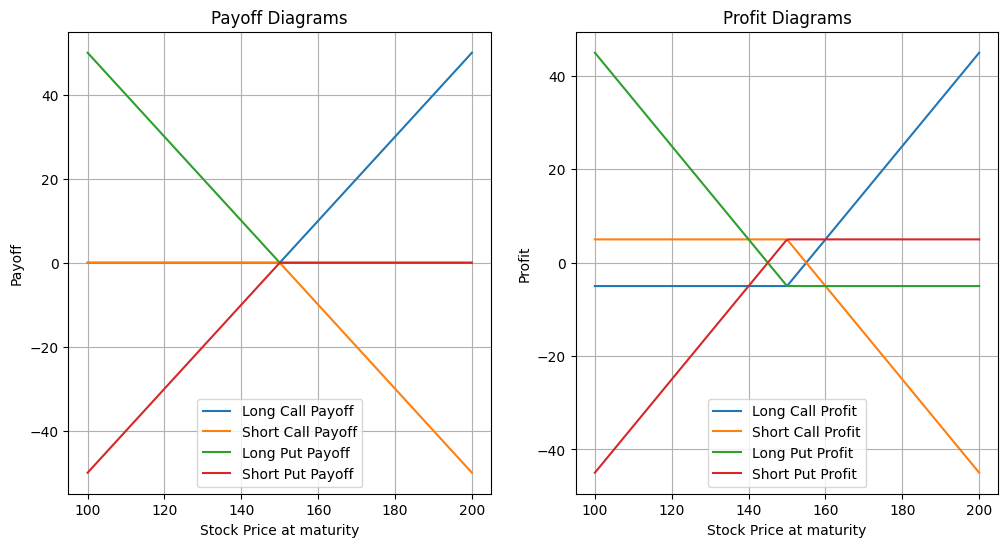

In [39]:
#A6Q5
import numpy as np 
import matplotlib.pyplot as plt 

#Parameters 
K = 150 #Strike Price
P = 5 #Premimum 
S = np.linspace(100, 200, 200) #Range of stock prices

#Payoff Calculations 
long_Call_Payoff = np.maximum(S-K, 0)
Short_Call_Payoff = - np.maximum(S-K, 0)
Long_Put_Payoff = np.maximum(K-S, 0)
Short_Put_Payoff = - np.maximum(K-S, 0) 

#Profit Calculations 
Long_Call_Profit = long_Call_Payoff - P
Short_Call_Profit = Short_Call_Payoff + P
Long_Put_Profit = Long_Put_Payoff - P
Short_Put_Profit = Short_Put_Payoff + P 

#Plot Payoff 
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1) 
plt.plot(S, long_Call_Payoff, label = "Long Call Payoff") 
plt.plot(S, Short_Call_Payoff, label = "Short Call Payoff") 
plt.plot(S, Long_Put_Payoff, label = "Long Put Payoff") 
plt.plot(S, Short_Put_Payoff, label = "Short Put Payoff") 
plt.title("Payoff Diagrams")
plt.xlabel("Stock Price at maturity")
plt.ylabel("Payoff")
plt.legend()
plt.grid(True) 

#Plot Profit 
plt.subplot(1, 2, 2) 
plt.plot(S, Long_Call_Profit, label = "Long Call Profit") 
plt.plot(S, Short_Call_Profit, label = "Short Call Profit") 
plt.plot(S, Long_Put_Profit, label = "Long Put Profit") 
plt.plot(S, Short_Put_Profit, label = "Short Put Profit") 
plt.title("Profit Diagrams")
plt.xlabel("Stock Price at maturity")
plt.ylabel("Profit")
plt.legend()
plt.grid(True) 
plt.show()



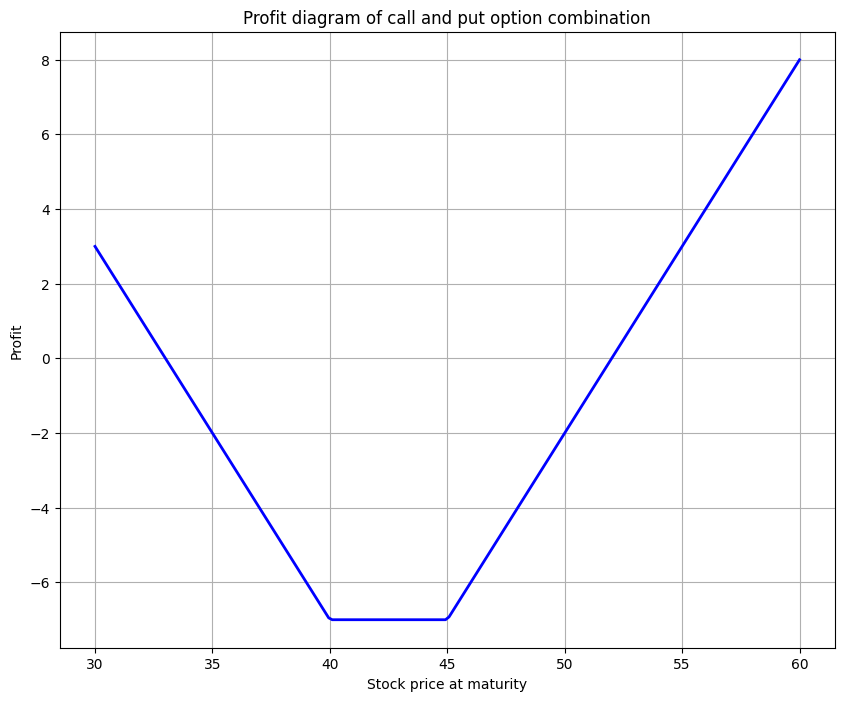

In [46]:
#A6Q6
import numpy as np 
import matplotlib.pyplot as plt 

#Given Data 
K_Call = 45 
C_Call = 3 
K_Put = 40 
C_Put = 4 
S = np.linspace(30, 60, 200) 

#Call and Put Profit 
profit_call = np.maximum(S-K_Call, 0) - C_Call
profit_put = np.maximum(K_Put - S, 0) - C_Put

#Total profit 
total_profit = profit_call + profit_put 

plt.figure(figsize=(10,8)) 
plt.plot( S, total_profit, label = "total profit", color = "blue", linewidth = 2) 
plt.title("Profit diagram of call and put option combination") 
plt.xlabel("Stock price at maturity") 
plt.ylabel("Profit") 
plt.grid(True) 
plt.show()

In [52]:
#A6Q7
import math 

#Given Data 
C = 1
S0 = 19
K = 20 
r = 0.03 
T = 4/12 

P = C + K * math.exp(-r*T) - S0

print(f"\nThe price of the European Put option is {P : .3f}\n")


The price of the European Put option is  1.801



In [57]:
#A6Q8
import numpy as np 
import scipy.stats as st 

#Black-Sholes Formula  
def black_scholes_call (S0, K, r, T, sigma) :
    d1 = (np.log(S0/K) + (r + sigma**2 / 2) * T ) / (sigma * np.sqrt(T)) 
    d2 = d1 - sigma * np.sqrt(T) 
    return S0*st.norm.cdf(d1) - K*np.exp(-r*T)*st.norm.cdf(d2) 
 
def black_scholes_put (S0, K, r, T, sigma) :
    d1 = (np.log(S0/K) + (r + sigma**2 / 2) * T ) / (sigma * np.sqrt(T)) 
    d2 = d1 - sigma * np.sqrt(T) 
    return K*np.exp(-r*T)*st.norm.cdf(-d2) - S0*st.norm.cdf(-d1) 

#Given Values 
S0 = 32
r = 0.05 
sigma = 0.3 

#Strike Price and Maturity 
k1, k2, k3 = 25, 30, 35 
t_half, t_one = 0.5, 1 

#Compute Individual option price 
call_25_6m = black_scholes_call (S0, k1, r, t_half, sigma) 
put_25_6m = black_scholes_put (S0, k1, r, t_half, sigma)  
call_30_6m = black_scholes_call (S0, k2, r, t_half, sigma) 
put_30_6m = black_scholes_put (S0, k2, r, t_half, sigma) 
call_35_6m = black_scholes_call (S0, k3, r, t_half, sigma) 

call_25_1y = black_scholes_call(S0, k1, r, t_one, sigma)
call_30_1y = black_scholes_call(S0, k2, r, t_one, sigma)
call_35_1y = black_scholes_call(S0, k3, r, t_one, sigma)

put_25_1y  = black_scholes_put(S0, k1, r, t_one, sigma)
put_30_1y  = black_scholes_put(S0, k2, r, t_one, sigma)
put_35_1y  = black_scholes_put(S0, k3, r, t_one, sigma) 

print("\nOption Prices : ")
print(f"call_25_6m : {call_25_6m: .4f}") 
print(f"put_25_6m : {put_25_6m : .4f}") 
print(f"call_30_6m : {call_30_6m: .4f}") 
print(f"put_30_6m : {put_30_6m : .4f}") 
print(f"call_25_1y : {call_25_1y : .4f}") 
print(f"call_30_1y : {call_30_1y : .4f}") 
print(f"call_35_1y : {call_35_1y : .4f}") 
print(f"put_25_1y : {put_25_1y : .4f}") 
print(f"put_30_1y : {put_30_1y : .4f}") 
print(f"put_35_1y : {put_35_1y : .4f}") 

#Strategy cost 
def bull_spread_calls():
    return call_25_6m - call_30_6m 

def bear_spread_puts():
    return put_30_6m - put_25_6m

def butterfly_calls(): 
    return call_25_1y - 2*call_30_1y + call_35_1y 

def butterfly_puts():
    return put_25_1y - 2*put_30_1y + put_35_1y 

def straddle():
    return call_30_6m + put_30_6m

def strangle():
    return call_35_6m + put_25_6m 

# Compute strategy costs
print("\nStrategy Costs:")
print(f"Bull Spread (Calls, 6m) = {bull_spread_calls():.4f}")
print(f"Bear Spread (Puts, 6m)  = {bear_spread_puts():.4f}")
print(f"Butterfly (Calls, 1y)    = {butterfly_calls():.4f}")
print(f"Butterfly (Puts, 1y)     = {butterfly_puts():.4f}")
print(f"Straddle (K=30, 6m)      = {straddle():.4f}")
print(f"Strangle (25-35, 6m)     = {strangle():.4f}") 

#Define table 
def profit_table():
    St = np.arange(10, 51, 2) #Final stock price 
    
    bull = np.maximum(St-k1, 0) - np.maximum(k2 - St, 0) - bull_spread_calls() 
    bear = np.maximum(k2 - St, 0) - np.maximum(k1 - St, 0) - bear_spread_puts() 
    butterfly_c = np.maximum(St-k1, 0) - 2* np.maximum(St-k2, 0) + np.maximum(St-k3, 0) - butterfly_calls()
    butterfly_p = np.maximum(k1-St, 0) - 2* np.maximum(k2-St, 0) + np.maximum(k3-St, 0) - butterfly_puts() 
    straddle_p  = (np.maximum(St-k2,0) + np.maximum(k2-St,0)) - straddle()
    strangle_p  = (np.maximum(St-k3,0) + np.maximum(k1-St,0)) - strangle() 

    print("\n St      bull       bear     butf_c     butf_p   strad_p     strang_p")
    print("-------------------------------------------------------------------------------")
    for i in range(len(St)):
        print(f" {St[i]},   {bull[i]: .3f},   {bear[i]: .3f},   {butterfly_c[i]: .3f},   {butterfly_p[i]: .3f},   {straddle_p[i]: .3f},   {strangle_p[i]: .3f}") 

profit_table()


Option Prices : 
call_25_6m :  7.8967
put_25_6m :  0.2794
call_30_6m :  4.1837
put_30_6m :  1.4430
call_25_1y :  8.9176
call_30_1y :  5.5982
call_35_1y :  3.2797
put_25_1y :  0.6984
put_30_1y :  2.1351
put_35_1y :  4.5728

Strategy Costs:
Bull Spread (Calls, 6m) = 3.7130
Bear Spread (Puts, 6m)  = 1.1636
Butterfly (Calls, 1y)    = 1.0009
Butterfly (Puts, 1y)     = 1.0009
Straddle (K=30, 6m)      = 5.6267
Strangle (25-35, 6m)     = 2.1328

 St      bull       bear     butf_c     butf_p   strad_p     strang_p
-------------------------------------------------------------------------------
 10,   -23.713,    3.836,   -1.001,   -1.001,    14.373,    12.867
 12,   -21.713,    3.836,   -1.001,   -1.001,    12.373,    10.867
 14,   -19.713,    3.836,   -1.001,   -1.001,    10.373,    8.867
 16,   -17.713,    3.836,   -1.001,   -1.001,    8.373,    6.867
 18,   -15.713,    3.836,   -1.001,   -1.001,    6.373,    4.867
 20,   -13.713,    3.836,   -1.001,   -1.001,    4.373,    2.867
 22,   -11.7

In [61]:
#A6Q9
import numpy as np
from scipy.stats import norm

# Given data
S0 = 30        # Current stock price
K = 29         # Strike price
r = 0.05       # Risk-free rate (annual)
sigma = 0.25   # Volatility
T = 4/12       # Time to maturity in years

# Step 1: Compute d1 and d2
d1 = (np.log(S0 / K) + (r + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
d2 = d1 - sigma * np.sqrt(T)

# Step 2: European Call Price
C_european = S0 * norm.cdf(d1) - K * np.exp(-r * T) * norm.cdf(d2)

# Step 3: American Call Price (same as European for non-dividend stock)
C_american = C_european

# Step 4: European Put Price
P_european = K * np.exp(-r * T) * norm.cdf(-d2) - S0 * norm.cdf(-d1)

# Step 5: Put-Call Parity Check
parity_lhs = C_european - P_european
parity_rhs = S0 - K * np.exp(-r * T)
parity_holds = np.isclose(parity_lhs, parity_rhs)

# Print results
print(f"European Call Price: ${C_european:.2f}")
print(f"American Call Price: ${C_american:.2f}")
print(f"European Put Price: ${P_european:.2f}")
print(f"Put-Call Parity holds: {parity_holds} (LHS={parity_lhs:.2f}, RHS={parity_rhs:.2f})")


European Call Price: $2.53
American Call Price: $2.53
European Put Price: $1.05
Put-Call Parity holds: True (LHS=1.48, RHS=1.48)


In [64]:
#A6Q10
import math 

#Given Data 
F0 = 60 
K = 60 
sigma = 0.3 
r = 0.08 
T = 0.5 
n = 2 

dt = T/n 
u = math.exp(sigma*math.sqrt(dt)) 
d = 1/u 
p = (1-d)/(u-d) 
disc = math.exp(-r*T)  

#Future price at maturity 
Fuu = F0 * u * u
Fud = F0
Fdd = F0 * d * d 

#Payoff at maturity 
C_uu = max(Fuu - K, 0)
C_ud = max(Fud - K, 0) 
C_dd = max(Fdd - K, 0) 

#Backward Step 
C_u = disc * (p*C_uu + (1-p)*C_ud)
C_d = disc * (p*C_ud + (1-p)*C_dd)

#Backward Step 2 (Initial Price)
C0 = disc * (p*C_u + (1-p)*C_d) 

print(f"\nEuropean Call option Value : {C0: .3f}")
print(f"American Call option value = Same as European (No early exercise advantage)\n")


European Call option Value :  4.146
American Call option value = Same as European (No early exercise advantage)



In [66]:
#A6Q11
import math 

#Parameters 
S0, K, r, q, T, sigma, N = 484, 480, 0.1, 0.03, 2/12, 0.25, 4 
dt = T/N 
u = math.exp(sigma*math.sqrt(dt))
d = 1/u 
p = (math.exp((r-q)*dt) - d)/ (u-d) 
disc = math.exp(-r*dt) 

values = [max(K - S0*(u**j)*(d**(N-j)) , 0) for j in range (N+1)] 

#Backward induction 
for i in range (N-1, -1, -1):
    new = []
    for j in range(i+1):
        cont = disc * (p*values[j+1] + (1-p)*values[j]) 
        intrinsic = max(K - S0*(u**j)*(d**(i-j)), 0)
        new.append(max(intrinsic, cont)) 
    values = new 

print("American Put option value: ", values[0]) 

American Put option value:  14.933233649496977
